# Olympics Athlete Data: Exploratory Data Analysis
**Team:** Ezekiel Galvez, Bryce Osborne, Christopher Munoz, Jinbang Bae

This notebook explores 120 years of Olympic history (Athens 1896 to Rio 2016). It imports, assesses,
cleans and tidies the data, then works through four questions from our dataset selection report:

1. Do physical attributes (height, weight, age) differ by sport, and do they relate to medaling?
2. How has female participation changed over time?
3. What explains differences in national medal performance?
4. Is there a measurable host-country advantage?

*Note: the analysis is descriptive. Correlation does not imply causation.*

## 1. Setup and Import

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Consistent look for every figure in the report
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
PALETTE = {"M": "#2b6cb0", "F": "#d9534f", "Summer": "#e0a100", "Winter": "#2c8fbf"}
MEDAL_COLORS = {"Gold": "#d4af37", "Silver": "#9a9a9a", "Bronze": "#b0703c"}

df = pd.read_csv("../data/olympics.csv")
df.head()

,id,name,sex,age,height,weight,team,noc,games,year,season,city,sport,event,medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


## 2. Assess the Data

In [2]:
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
print(f"Unique athletes: {df['id'].nunique():,}   Sports: {df['sport'].nunique()}   "
      f"Events: {df['event'].nunique()}   NOCs: {df['noc'].nunique()}")
print(f"Years: {df['year'].min()} to {df['year'].max()}")
df.info()

Rows: 271,116   Columns: 15
Unique athletes: 135,571   Sports: 66   Events: 765   NOCs: 230
Years: 1896 to 2016
<class 'pandas.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   id      271116 non-null  int64  
 1   name    271116 non-null  str    
 2   sex     271116 non-null  str    
 3   age     261642 non-null  float64
 4   height  210945 non-null  float64
 5   weight  208241 non-null  float64
 6   team    271116 non-null  str    
 7   noc     271116 non-null  str    
 8   games   271116 non-null  str    
 9   year    271116 non-null  int64  
 10  season  271116 non-null  str    
 11  city    271116 non-null  str    
 12  sport   271116 non-null  str    
 13  event   271116 non-null  str    
 14  medal   39783 non-null   str    
dtypes: float64(3), int64(2), str(10)
memory usage: 56.6 MB


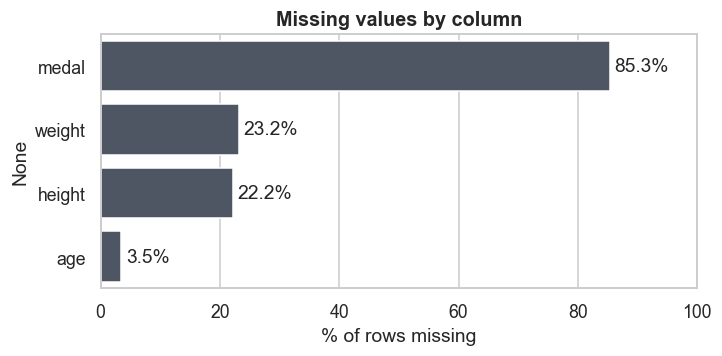

In [3]:
# Missingness per column, as a share of rows
missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(7, 3))
sns.barplot(x=missing.values, y=missing.index, color="#4a5568", ax=ax)
for i, v in enumerate(missing.values):
    ax.text(v + 0.8, i, f"{v}%", va="center")
ax.set_xlim(0, 100)
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values by column")
plt.show()

**Observations.** `medal` is "missing" for 85% of rows, but that just means the athlete did not medal, so it is
not a data problem. `height` and `weight` are genuinely missing for roughly a quarter of rows. `age` is
missing for about 3%. Next we check whether the height/weight gaps are concentrated in early games.

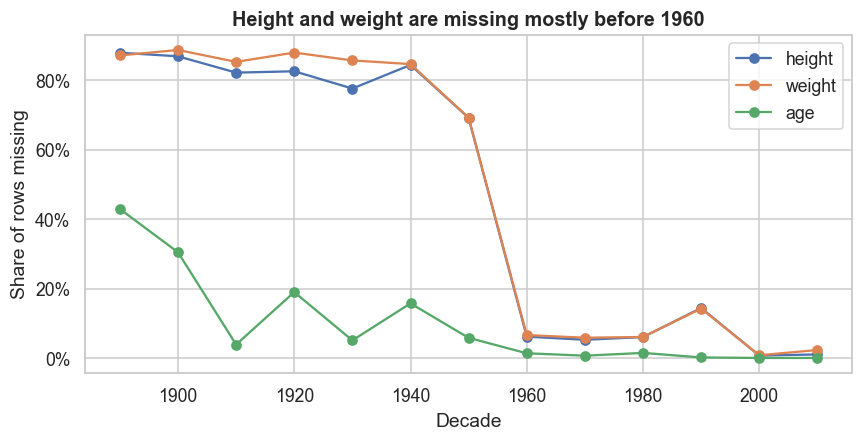

In [4]:
# Is physical-attribute missingness concentrated in older games?
miss_by_decade = (
    df.assign(decade=(df["year"] // 10) * 10)
      .groupby("decade")[["height", "weight", "age"]]
      .apply(lambda g: g.isna().mean() * 100)
)

fig, ax = plt.subplots(figsize=(9, 4))
miss_by_decade.plot(ax=ax, marker="o")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Decade")
ax.set_ylabel("Share of rows missing")
ax.set_title("Height and weight are missing mostly before 1960")
plt.show()

In [5]:
# Other checks: exact duplicate rows and implausible values
print("Exact duplicate rows:", df.duplicated().sum())
print(df[["age", "height", "weight"]].describe().round(1))
print()
print("Oldest competitors:")
print(df.nlargest(5, "age")[["name", "age", "sport", "year"]].to_string(index=False))

Exact duplicate rows: 1385
            age    height    weight
count  261642.0  210945.0  208241.0
mean       25.6     175.3      70.7
std         6.4      10.5      14.3
min        10.0     127.0      25.0
25%        21.0     168.0      60.0
50%        24.0     175.0      70.0
75%        28.0     183.0      79.0
max        97.0     226.0     214.0

Oldest competitors:
                      name  age            sport  year
    John Quincy Adams Ward 97.0 Art Competitions  1928
             Winslow Homer 96.0 Art Competitions  1932
Thomas Cowperthwait Eakins 88.0 Art Competitions  1932
Thomas Cowperthwait Eakins 88.0 Art Competitions  1932
Thomas Cowperthwait Eakins 88.0 Art Competitions  1932


There are 1,385 exact duplicate rows (the same athlete, event and games entered twice), so we drop them. The oldest competitors (ages 90+) are
from the Olympic **art competitions** (the data lists them under sports such as Art Competitions), so they are
legitimate records but not typical athletes.

## 3. Clean and Tidy

In [6]:
clean = df.drop_duplicates().copy()

# Medal 'NA' means no medal: build an explicit binary indicator plus a labelled column
clean["medal"] = clean["medal"].fillna("No medal")
clean["won_medal"] = (clean["medal"] != "No medal").astype(int)

# BMI is a handy combined body-size measure (kg / m^2)
clean["bmi"] = clean["weight"] / (clean["height"] / 100) ** 2

# Sport-level 'Art Competitions' are not athletic events; keep them out of physical analysis
clean["is_art"] = clean["sport"].eq("Art Competitions")

# Short event name: the event column repeats the sport name as a prefix
clean["event_short"] = clean.apply(lambda r: r["event"].replace(r["sport"], "", 1).strip(), axis=1)

# Treat the 1906 Intercalated Games as ordinary Summer data (they are in the file already)
modern = clean[(clean["year"] >= 1960) & (~clean["is_art"])]

print(f"After cleaning: {len(clean):,} rows   (modern subset 1960+: {len(modern):,})")
clean[["name", "sex", "age", "sport", "year", "medal", "won_medal", "bmi"]].head()

After cleaning: 269,731 rows   (modern subset 1960+: 209,072)


,name,sex,age,sport,year,medal,won_medal,bmi
0,A Dijiang,M,24.0,Basketball,1992,No medal,0,24.691358
1,A Lamusi,M,23.0,Judo,2012,No medal,0,20.761246
2,Gunnar Nielsen Aaby,M,24.0,Football,1920,No medal,0,NaN
3,Edgar Lindenau Aabye,M,34.0,Tug-Of-War,1900,Gold,1,NaN
4,Christine Jacoba Aaftink,F,21.0,Speed Skating,1988,No medal,0,23.959094


In [7]:
# Medal tally rule: a team medal is ONE medal for the country, not one per athlete.
# Deduplicate by games + event + NOC + medal before counting.
medals = clean[clean["won_medal"] == 1]
medal_events = (
    medals.drop_duplicates(subset=["games", "event", "noc", "medal"])
          .copy()
)
print(f"Athlete-level medal rows: {len(medals):,}")
print(f"Country-level medals after de-duplication: {len(medal_events):,}")

Athlete-level medal rows: 39,772
Country-level medals after de-duplication: 18,905


## 4. Exploratory Data Analysis

### 4.1 The shape of the Games: growth over time

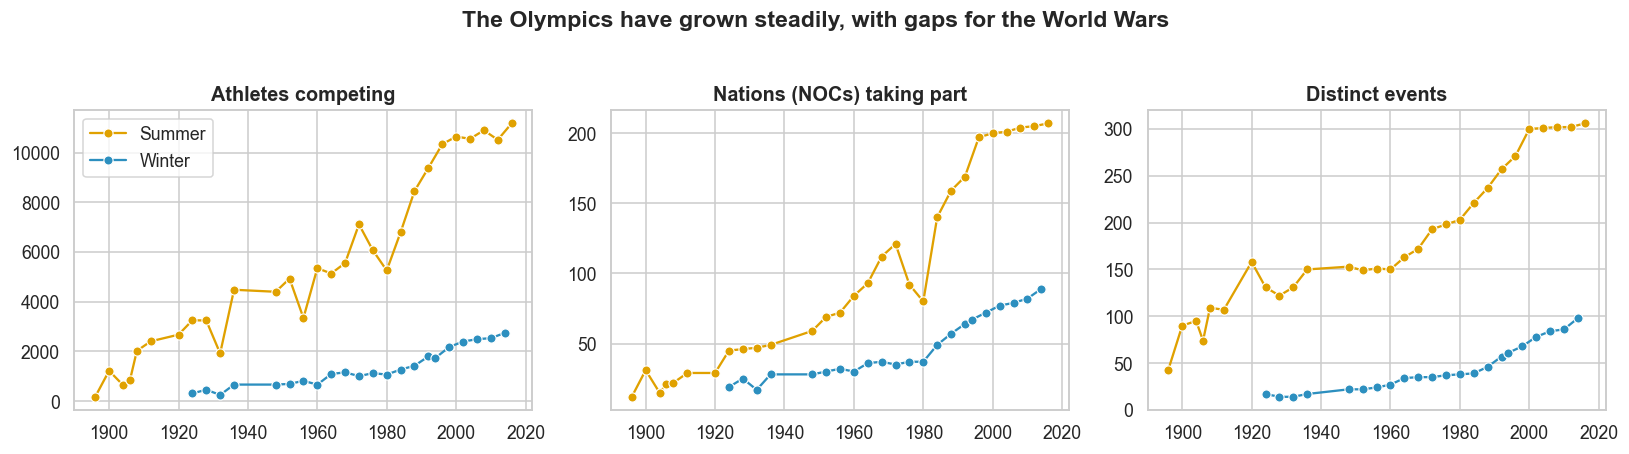

In [8]:
growth = (
    clean.groupby(["year", "season"])
         .agg(athletes=("id", "nunique"), nocs=("noc", "nunique"), events=("event", "nunique"))
         .reset_index()
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, col, title in zip(axes, ["athletes", "nocs", "events"],
                          ["Athletes competing", "Nations (NOCs) taking part", "Distinct events"]):
    sns.lineplot(data=growth, x="year", y=col, hue="season", palette=PALETTE, marker="o", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
axes[0].legend(title="")
axes[1].get_legend().remove(); axes[2].get_legend().remove()
fig.suptitle("The Olympics have grown steadily, with gaps for the World Wars", y=1.03, fontweight="bold")
plt.tight_layout()
plt.show()

Participation climbs from 176 athletes in 1896 to about 11,200 at the 2016 Summer Games. The missing
Summer games in 1916, 1940 and 1944 are the cancelled World War games. The Winter Games (since 1924) stay much smaller.

### 4.2 Question 2: How has female participation changed?

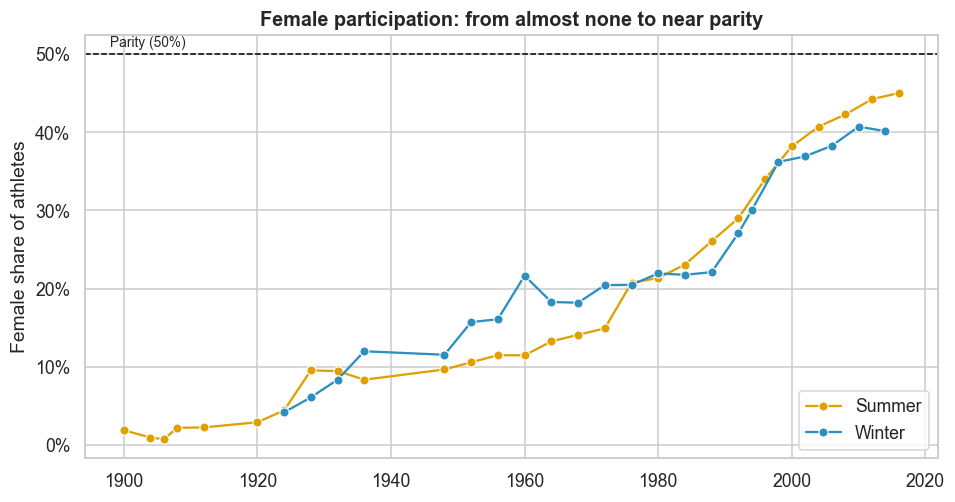

,year,season,sex,share
2,1900,Summer,F,0.018791
34,1952,Summer,F,0.105637
36,1952,Winter,F,0.157061
100,2016,Summer,F,0.450309


In [9]:
sex_year = (
    clean[~clean["is_art"]]
    .drop_duplicates(subset=["id", "games"])          # one row per athlete per games
    .groupby(["year", "season"])["sex"]
    .value_counts(normalize=True).rename("share").reset_index()
)
fem = sex_year[sex_year["sex"] == "F"]

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=fem, x="year", y="share", hue="season", palette=PALETTE, marker="o", ax=ax)
ax.axhline(0.5, color="black", ls="--", lw=1)
ax.text(1898, 0.51, "Parity (50%)", fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylabel("Female share of athletes")
ax.set_xlabel("")
ax.set_title("Female participation: from almost none to near parity")
ax.legend(title="")
plt.show()

latest = fem[fem["year"].isin([1900, 1952, 2016])]
latest

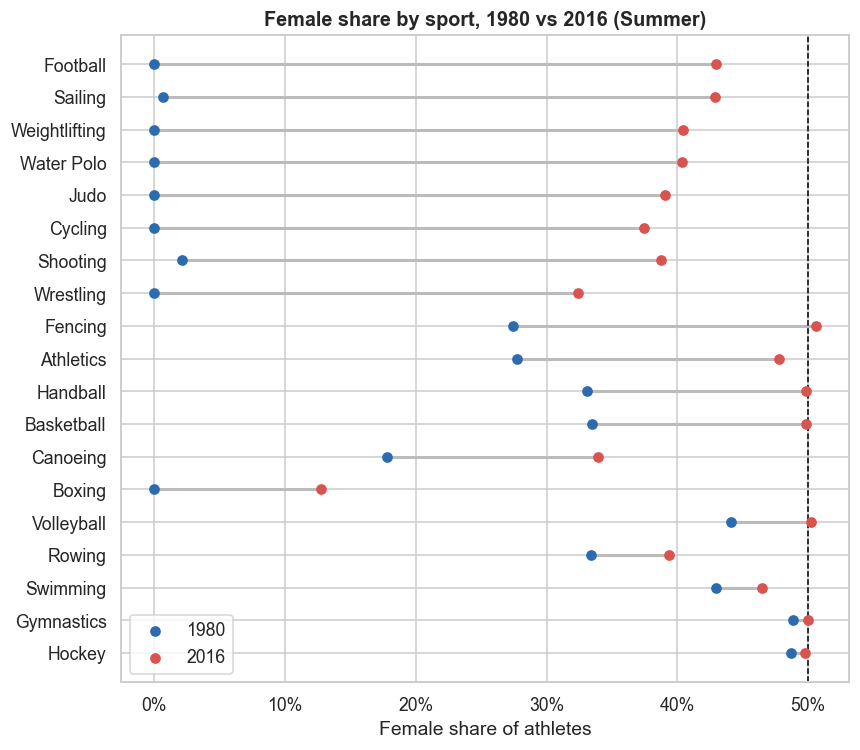

In [10]:
# Which sports drove the change? Female share in 1980 vs 2016 (Summer, sports with 100+ athletes each year)
def female_share(year):
    d = (clean[(clean["year"] == year) & (clean["season"] == "Summer") & ~clean["is_art"]]
         .drop_duplicates(subset=["id"]))
    g = d.groupby("sport")["sex"].agg(total="size", female=lambda s: (s == "F").mean())
    return g[g["total"] >= 100]["female"]

compare = pd.concat({"1980": female_share(1980), "2016": female_share(2016)}, axis=1).dropna()
compare["change"] = compare["2016"] - compare["1980"]
compare = compare.sort_values("change")

fig, ax = plt.subplots(figsize=(8, 7))
ax.hlines(compare.index, compare["1980"], compare["2016"], color="#bbb", lw=2)
ax.scatter(compare["1980"], compare.index, color="#2b6cb0", label="1980", zorder=3)
ax.scatter(compare["2016"], compare.index, color="#d9534f", label="2016", zorder=3)
ax.axvline(0.5, color="black", ls="--", lw=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Female share of athletes")
ax.set_title("Female share by sport, 1980 vs 2016 (Summer)")
ax.legend()
plt.tight_layout()
plt.show()

Women's share of the Summer Games grew from about 21% in 1980 to 45% in 2016 (and just 2% in 1900). Many sports
that had almost no women in 1980 (judo, cycling, weightlifting, football, sailing, water polo) are now at 35-45%,
while gymnastics, hockey, basketball and handball sit near 50%. Boxing is the clear laggard at 13%, as women's boxing
only joined the programme in 2012. Parity has been reached unevenly, and only sports with 100+ athletes in both
years are shown.

### 4.3 Question 1: Physical attributes by sport and medal success

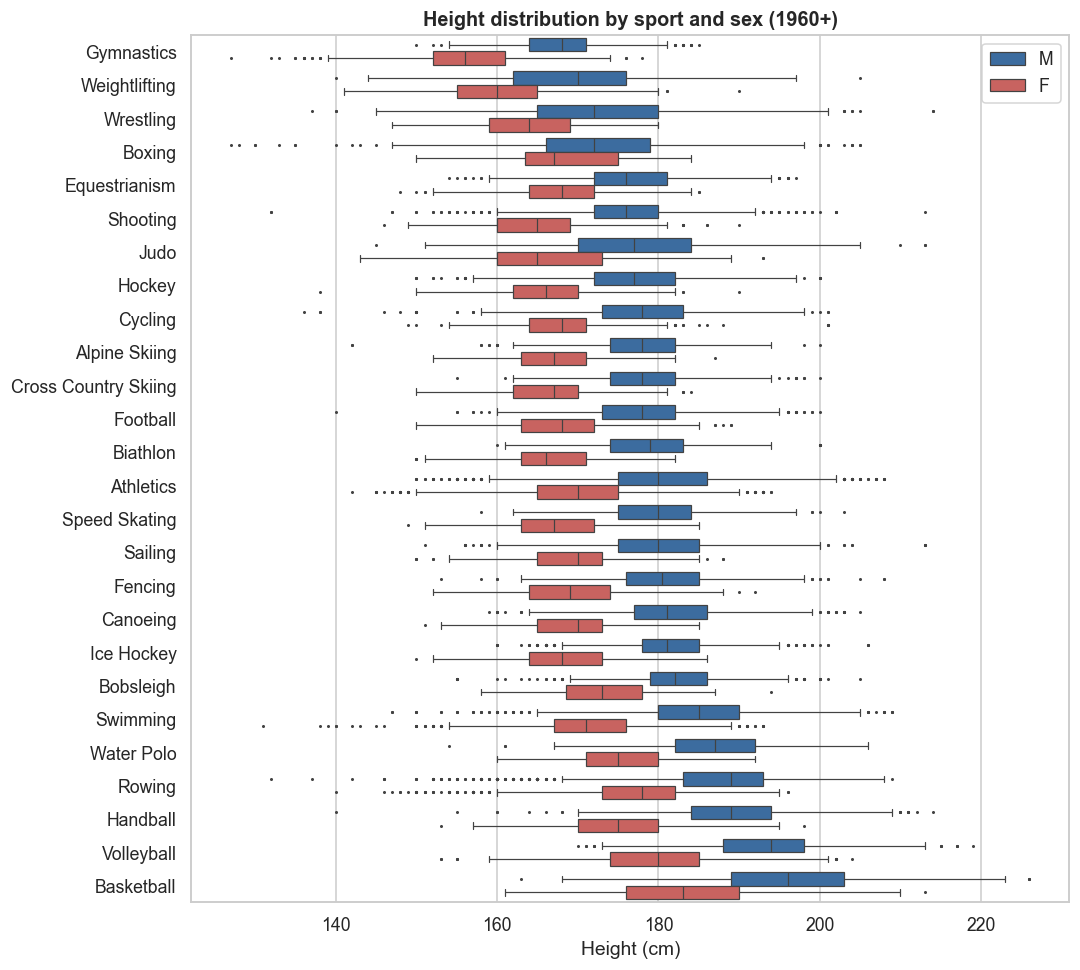

In [11]:
# Modern-era athletes with known height and weight; sports with enough athletes to compare
phys = modern.dropna(subset=["height", "weight"]).drop_duplicates(subset=["id", "games", "sport"])
top_sports = phys["sport"].value_counts()
top_sports = top_sports[top_sports >= 1500].index
phys = phys[phys["sport"].isin(top_sports)]

order = (phys[phys["sex"] == "M"].groupby("sport")["height"].median().sort_values().index)

fig, ax = plt.subplots(figsize=(10, 9))
sns.boxplot(data=phys, y="sport", x="height", hue="sex", order=order, palette=PALETTE,
            fliersize=1, linewidth=0.8, ax=ax)
ax.set_xlabel("Height (cm)")
ax.set_ylabel("")
ax.set_title("Height distribution by sport and sex (1960+)")
ax.legend(title="")
plt.tight_layout()
plt.show()

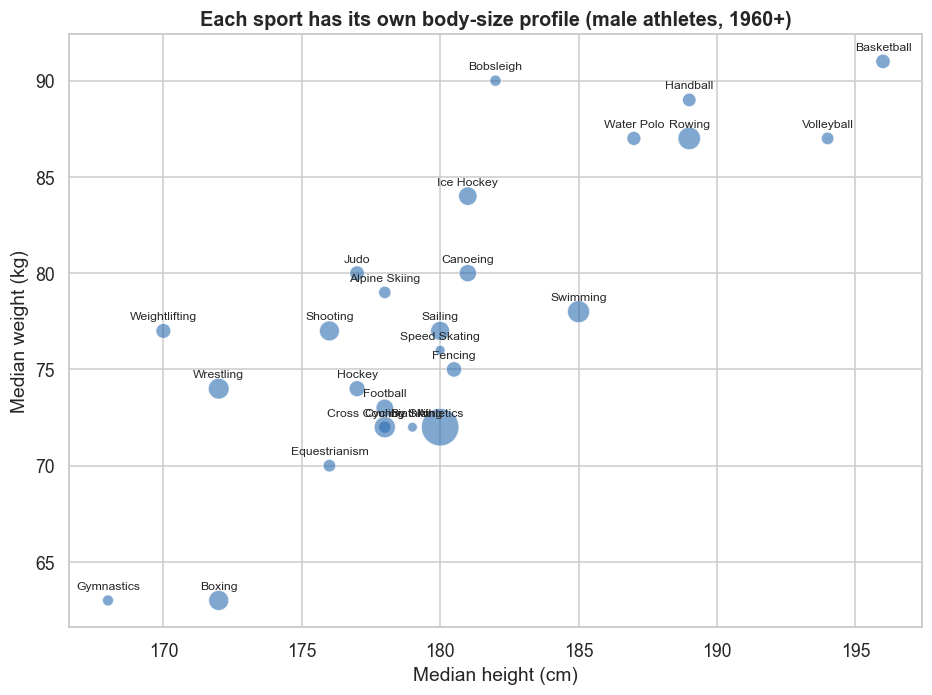

In [12]:
# Body-size map: median height vs median weight per sport (males), bubble = number of athletes
male = phys[phys["sex"] == "M"]
prof = male.groupby("sport").agg(height=("height", "median"), weight=("weight", "median"),
                                 n=("id", "size")).reset_index()

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=prof, x="height", y="weight", size="n", sizes=(40, 600),
                color="#2b6cb0", alpha=0.6, legend=False, ax=ax)
for _, r in prof.iterrows():
    ax.annotate(r["sport"], (r["height"], r["weight"]), fontsize=8, ha="center", va="bottom",
                xytext=(0, 6), textcoords="offset points")
ax.set_xlabel("Median height (cm)")
ax.set_ylabel("Median weight (kg)")
ax.set_title("Each sport has its own body-size profile (male athletes, 1960+)")
plt.show()

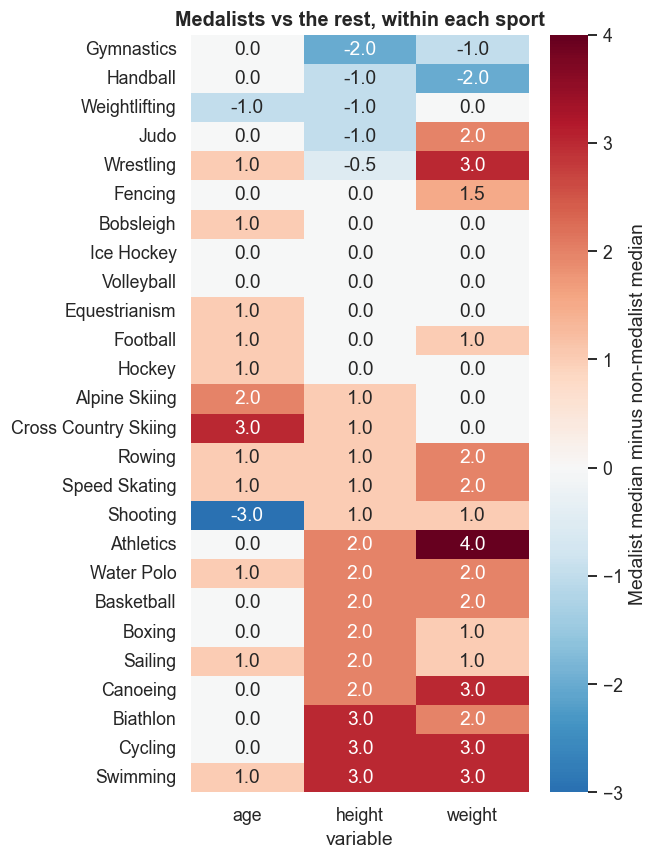

In [13]:
# Do medalists differ from non-medalists, WITHIN a sport? (difference in median, medalist minus the rest)
rows = []
for sport, g in phys.groupby("sport"):
    for var in ["height", "weight", "age"]:
        gg = g.dropna(subset=[var])
        med = gg.loc[gg["won_medal"] == 1, var]
        non = gg.loc[gg["won_medal"] == 0, var]
        if len(med) >= 30:
            rows.append({"sport": sport, "variable": var, "diff": med.median() - non.median()})
diff = pd.DataFrame(rows).pivot(index="sport", columns="variable", values="diff")

fig, ax = plt.subplots(figsize=(6, 8))
sns.heatmap(diff.sort_values("height"), annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax,
            cbar_kws={"label": "Medalist median minus non-medalist median"})
ax.set_title("Medalists vs the rest, within each sport")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Height and weight differ hugely **between** sports (basketball and volleyball tower over gymnastics), but
**within** a sport the medalist-vs-rest differences are small: the median gap is usually 0 to 2 cm in height,
0 to 2 kg in weight and 0 to 1 year in age, and no sport shows more than about 4 units. Where a gap exists it usually favours medalists being slightly taller and heavier (swimming, cycling, athletics); gymnastics is the exception, where medalists are a little shorter. Body type decides which sport an athlete is in far more than it decides who wins within it.

### 4.4 Question 3: National medal performance

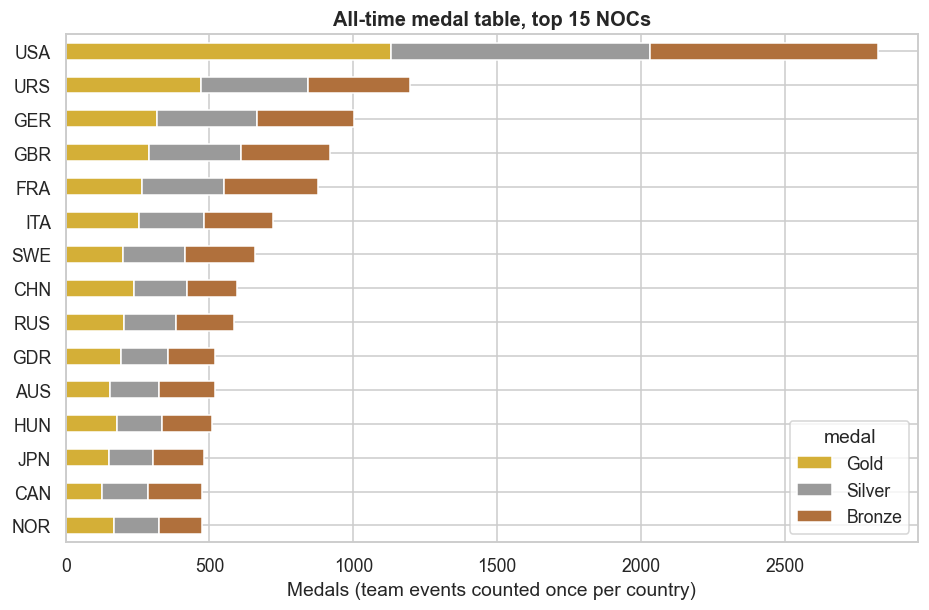

medal,Gold,Silver,Bronze,Total
noc,,,,
USA,1131,901,791,2823
URS,471,373,353,1197
GER,319,345,340,1004
GBR,289,320,310,919
FRA,264,286,329,879
ITA,256,225,241,722
SWE,200,215,242,657
CHN,239,184,172,595
RUS,202,183,199,584


In [14]:
tally = (medal_events.groupby("noc")["medal"].value_counts().unstack(fill_value=0)
         .reindex(columns=["Gold", "Silver", "Bronze"]))
tally["Total"] = tally.sum(axis=1)
top = tally.sort_values("Total", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 6))
top[["Gold", "Silver", "Bronze"]].plot(kind="barh", stacked=True, ax=ax,
                                       color=[MEDAL_COLORS[m] for m in ["Gold", "Silver", "Bronze"]])
ax.invert_yaxis()
ax.set_xlabel("Medals (team events counted once per country)")
ax.set_ylabel("")
ax.set_title("All-time medal table, top 15 NOCs")
plt.show()
top

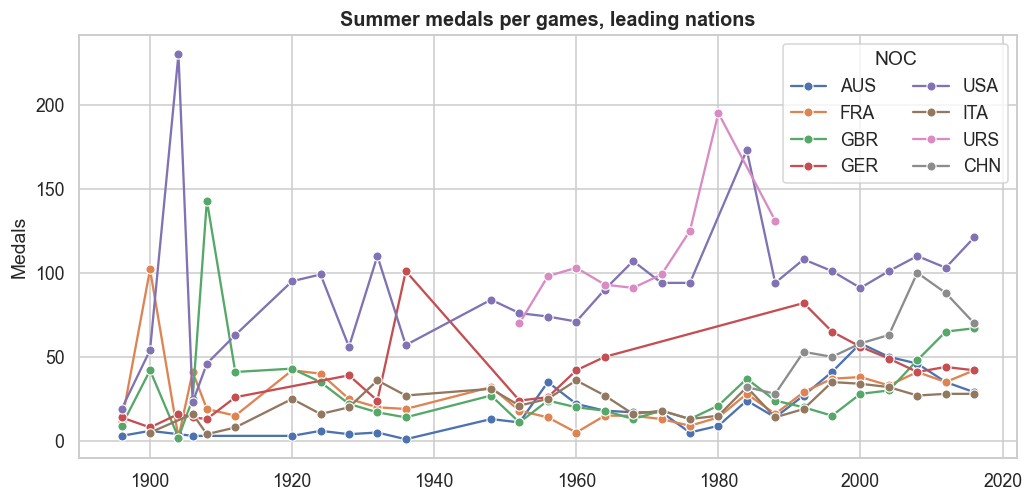

In [15]:
# Medals over time for the leading nations (Summer games, 5-year bins would blur; use per-games counts)
leaders = ["USA", "URS", "GER", "GBR", "FRA", "CHN", "ITA", "AUS"]
over_time = (medal_events[(medal_events["season"] == "Summer") & medal_events["noc"].isin(leaders)]
             .groupby(["year", "noc"]).size().rename("medals").reset_index())

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=over_time, x="year", y="medals", hue="noc", marker="o", ax=ax)
ax.set_title("Summer medals per games, leading nations")
ax.set_ylabel("Medals")
ax.set_xlabel("")
ax.legend(title="NOC", ncol=2)
plt.show()

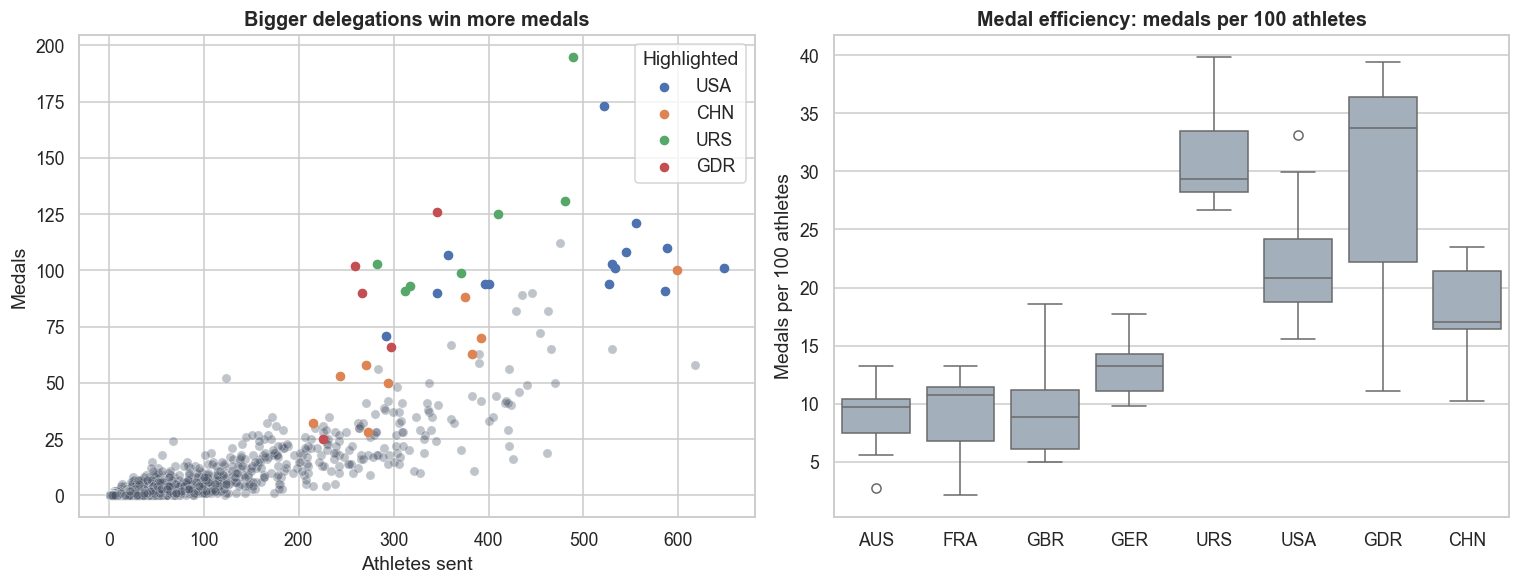

Correlation of athletes sent vs medals won: 0.83


In [16]:
# What explains medal counts: delegation size or something else?
# One point per NOC per Summer games since 1960: team size vs medals won.
size = (clean[(clean["season"] == "Summer") & (clean["year"] >= 1960)]
        .groupby(["year", "noc"])["id"].nunique().rename("athletes"))
won = (medal_events[(medal_events["season"] == "Summer") & (medal_events["year"] >= 1960)]
       .groupby(["year", "noc"]).size().rename("medals"))
nd = pd.concat([size, won], axis=1).fillna({"medals": 0}).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=nd, x="athletes", y="medals", alpha=0.35, color="#4a5568", ax=axes[0])
for noc in ["USA", "CHN", "URS", "GDR"]:
    r = nd[nd["noc"] == noc]
    axes[0].scatter(r["athletes"], r["medals"], s=28, label=noc)
axes[0].legend(title="Highlighted")
axes[0].set_title("Bigger delegations win more medals")
axes[0].set_xlabel("Athletes sent")
axes[0].set_ylabel("Medals")

nd["medals_per_100"] = nd["medals"] / nd["athletes"] * 100
big = nd[nd["athletes"] >= 100]
sns.boxplot(data=big[big["noc"].isin(["USA", "URS", "GDR", "CHN", "GBR", "AUS", "GER", "FRA"])],
            x="noc", y="medals_per_100", color="#a0aec0", ax=axes[1])
axes[1].set_title("Medal efficiency: medals per 100 athletes")
axes[1].set_xlabel("")
axes[1].set_ylabel("Medals per 100 athletes")
plt.tight_layout()
plt.show()

print("Correlation of athletes sent vs medals won:",
      round(nd[["athletes", "medals"]].corr().iloc[0, 1], 2))

Delegation size is a strong predictor of medal count (correlation 0.83), but efficiency varies: the median
Soviet team won about 29 medals per 100 athletes and East Germany about 34, against about 21 for the USA, 17 for China and
under 14 for Great Britain, Australia, Germany and France. Note that medal totals here count each team medal once, so
the USA total (2,823) is lower than the raw athlete-level count of 5,637 in our dataset report. That points to
**sport specialization** and state-backed programs, which later analysis can test with sport-level data.

### 4.5 Question 4: Host-country advantage

In [17]:
# City -> host NOC mapping (Summer and Winter games in the data)
host_noc = {
    "Athina": "GRE", "Paris": "FRA", "St. Louis": "USA", "London": "GBR", "Stockholm": "SWE",
    "Antwerpen": "BEL", "Amsterdam": "NED", "Los Angeles": "USA", "Berlin": "GER", "Helsinki": "FIN",
    "Melbourne": "AUS", "Roma": "ITA", "Tokyo": "JPN", "Mexico City": "MEX", "Munich": "GER",
    "Montreal": "CAN", "Moskva": "URS", "Seoul": "KOR", "Barcelona": "ESP", "Atlanta": "USA",
    "Sydney": "AUS", "Beijing": "CHN", "Rio de Janeiro": "BRA",
    "Chamonix": "FRA", "Sankt Moritz": "SUI", "Lake Placid": "USA", "Garmisch-Partenkirchen": "GER",
    "Oslo": "NOR", "Cortina d'Ampezzo": "ITA", "Squaw Valley": "USA", "Innsbruck": "AUT",
    "Grenoble": "FRA", "Sapporo": "JPN", "Sarajevo": "YUG", "Calgary": "CAN", "Albertville": "FRA",
    "Lillehammer": "NOR", "Nagano": "JPN", "Salt Lake City": "USA", "Torino": "ITA",
    "Vancouver": "CAN", "Sochi": "RUS",
}
games = clean[["games", "year", "season", "city"]].drop_duplicates()
games["host"] = games["city"].map(host_noc)
print("Cities with no host mapping:", games[games["host"].isna()]["city"].unique())

# Medals per NOC per games, with a flag for when the NOC is the host
per = (medal_events.groupby(["games", "noc"]).size().rename("medals").reset_index()
       .merge(games, on="games"))
per["is_host"] = per["noc"] == per["host"]

# For every host, compare its medals as host vs its average in the games just before/after
rows = []
for _, g in games.dropna(subset=["host"]).iterrows():
    same = per[(per["noc"] == g["host"]) & (per["season"] == g["season"])].sort_values("year")
    host_row = same[same["games"] == g["games"]]
    others = same[(same["games"] != g["games"]) &
                  (same["year"].between(g["year"] - 12, g["year"] + 12))]
    if len(host_row) and len(others):
        rows.append({"games": g["games"], "host": g["host"],
                     "host_medals": host_row["medals"].iloc[0],
                     "baseline": others["medals"].mean()})
host_df = pd.DataFrame(rows)
host_df["uplift"] = host_df["host_medals"] / host_df["baseline"]
host_df.sort_values("uplift", ascending=False).head(10).round(2)

Cities with no host mapping: <ArrowStringArray>
[]
Length: 0, dtype: str


,games,host,host_medals,baseline,uplift
2,1920 Summer,BEL,42,6.20,6.77
3,1900 Summer,FRA,102,17.60,5.80
43,1904 Summer,USA,230,41.00,5.61
45,1908 Summer,GBR,143,27.00,5.30
26,1968 Summer,MEX,9,1.86,4.85
48,1936 Winter,GER,6,1.50,4.00
49,1896 Summer,GRE,44,13.67,3.22
28,1936 Summer,GER,101,31.50,3.21
40,1972 Winter,JPN,3,1.00,3.00
38,1968 Winter,FRA,9,3.00,3.00


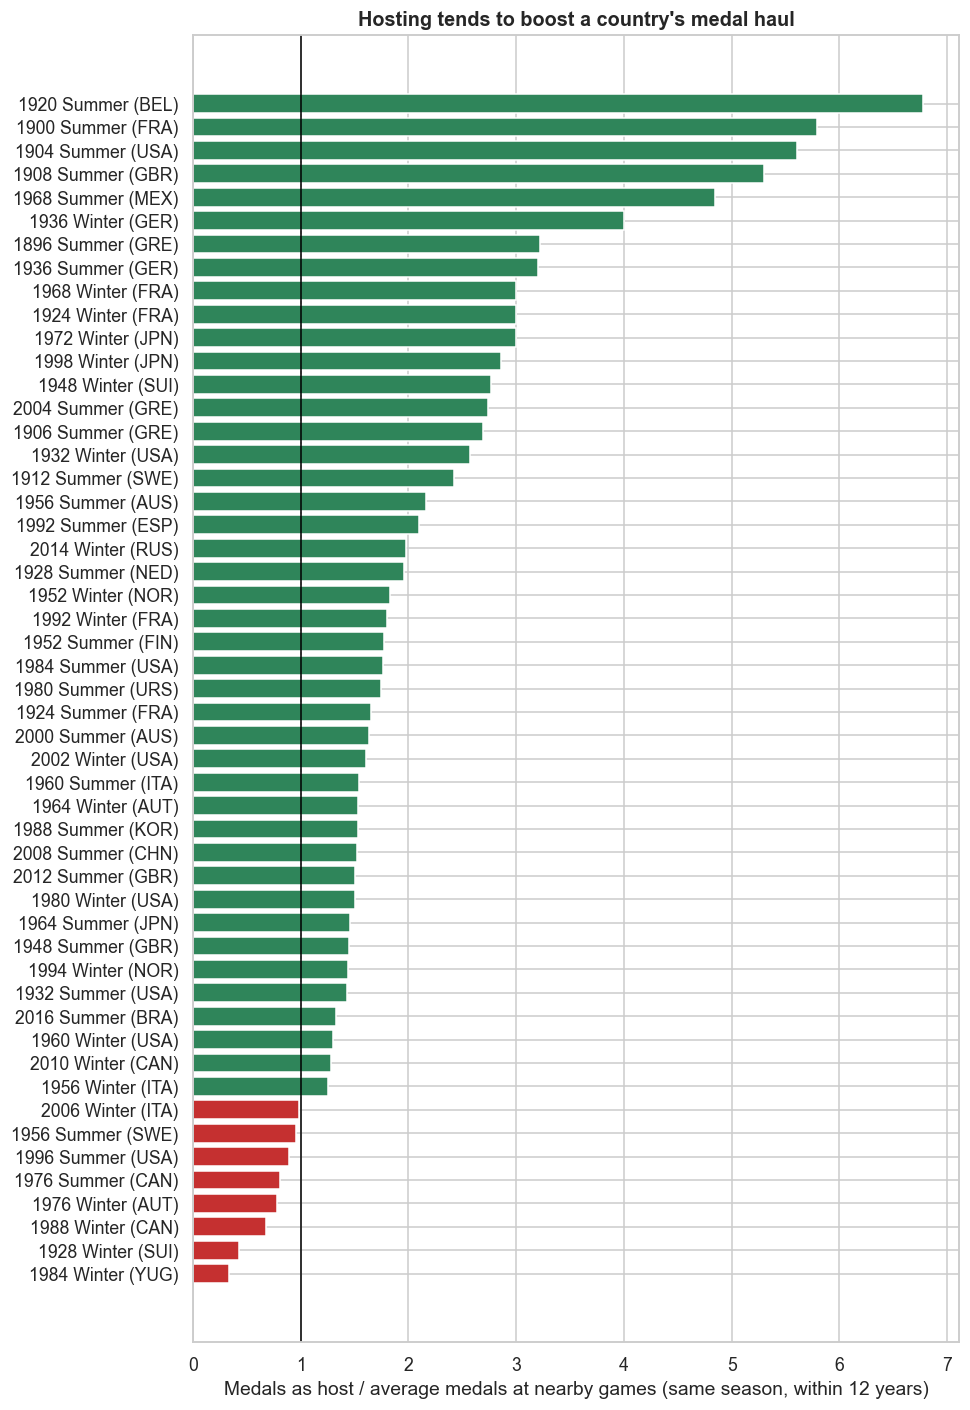

Hosts that out-performed their baseline: 84%
Median uplift: 1.75x


In [18]:
fig, ax = plt.subplots(figsize=(9, 13))
plot_df = host_df.sort_values("uplift")
colors = np.where(plot_df["uplift"] >= 1, "#2f855a", "#c53030")
ax.barh(plot_df["games"] + " (" + plot_df["host"] + ")", plot_df["uplift"], color=colors)
ax.axvline(1, color="black", lw=1)
ax.set_xlabel("Medals as host / average medals at nearby games (same season, within 12 years)")
ax.set_title("Hosting tends to boost a country's medal haul")
plt.tight_layout()
plt.show()

print(f"Hosts that out-performed their baseline: {(host_df['uplift'] > 1).mean():.0%}")
print(f"Median uplift: {host_df['uplift'].median():.2f}x")

84% of host nations win more medals at home than at neighbouring games, with a median uplift of 1.75x. The very
largest uplifts come from the early games (1900, 1904, 1908, 1920), when fields were tiny and hosts entered far larger
teams, so the modern era is a fairer test. The data cannot say *why* (home crowds, automatic qualification, bigger delegations, travel); it only shows
the association. A later step could control for delegation size.

### 4.6 Bonus: the age of Olympians

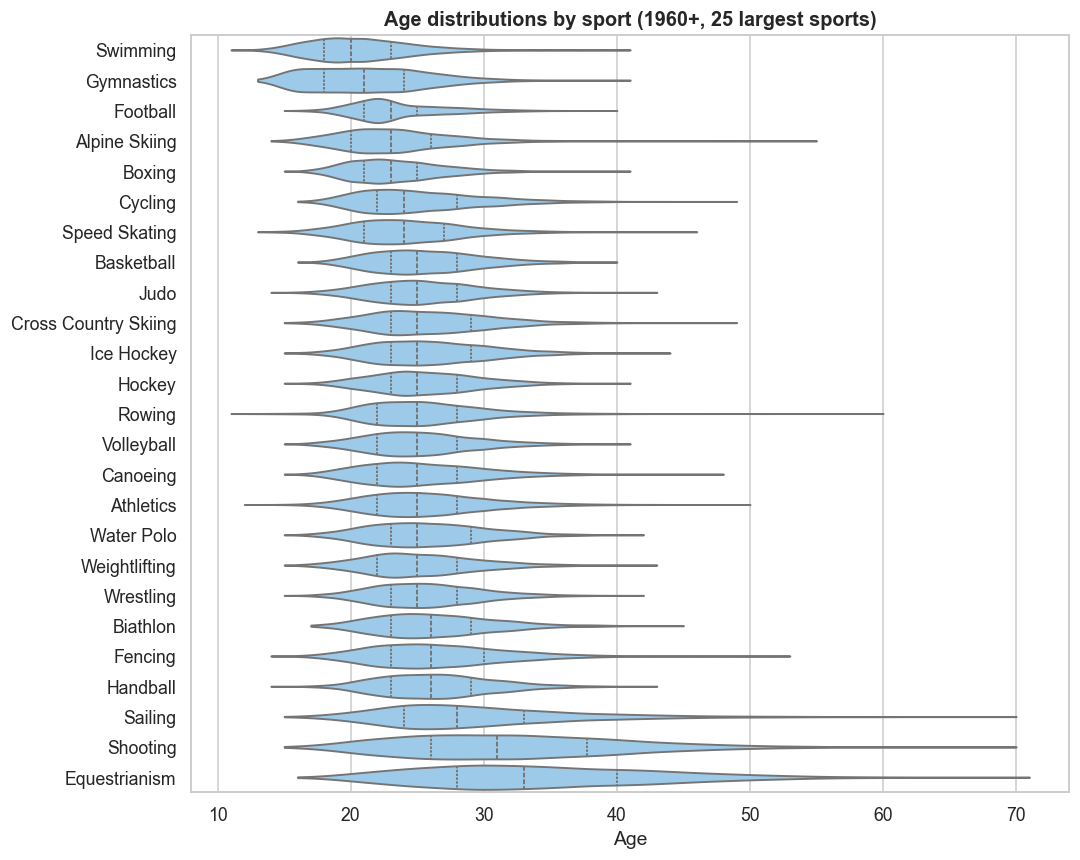

In [19]:
age_sport = modern.dropna(subset=["age"]).drop_duplicates(subset=["id", "games", "sport"])
age_sport = age_sport[age_sport["sport"].isin(age_sport["sport"].value_counts().head(25).index)]
order = age_sport.groupby("sport")["age"].median().sort_values().index

fig, ax = plt.subplots(figsize=(10, 8))
sns.violinplot(data=age_sport, y="sport", x="age", order=order, color="#90cdf4",
               inner="quartile", cut=0, density_norm="width", ax=ax)
ax.set_xlabel("Age")
ax.set_ylabel("")
ax.set_title("Age distributions by sport (1960+, 25 largest sports)")
plt.tight_layout()
plt.show()

## 5. Summary of Findings (so far)
- **Growth:** the Games grew from 176 athletes to over 11,000, with the World Wars the only interruptions.
- **Women:** female participation rose from almost none to about 45% in 2016, but sport-level parity is uneven.
- **Body type:** physique differs strongly between sports but only weakly between medalists and others within a sport.
- **Nations:** delegation size explains most of the variation in medal counts; Eastern Bloc teams were unusually efficient.
- **Hosts:** the majority of host nations beat their own baseline.

## 6. Next Steps
- Logistic regression of medal status on height, weight and age, by sport.
- Control host advantage for delegation size.
- Handle historical NOCs (URS, GDR, FRG) explicitly for long-run country comparisons.
- Interactive plotly versions of the strongest figures.